# LAB 04 — Earth as an Exoplanet: PSG spektri
**Astrobiologija**  
**Ime i prezime:** Aleksa Boskovic  **Indeks:** 172/22

> **Istraživačko pitanje:** Kako prepoznajemo atmosferske karakteristike Zemlje iz reflektovane svetlosti ili termalne emisije?

**Pravila rada:** Realne modele generišete u **NASA Planetary Spectrum Generator (PSG)**, a u ovom notebooku proveravate konfiguracije, čitate stvarne ASCII izlaze, crtate i tumačite spektre. Demonstracioni račun ili grafik u Pythonu **nije PSG simulacija**. **Ne izmišljajte podatke ako server nije dostupan**


# I. Teorijski uvod
## 1. Zemlja posmatrana kao egzoplaneta

U astronomiji egzoplaneta obično merimo ukupnu svetlost ili promenu svetlosti zvezde i planete, a ne detalje površine. Zemlja kao testni slučaj omogućava proveru metoda na atmosferi čiji su sastav i fizički procesi dobro proučeni. **Prisustvo spektralne karakteristike nije automatski dokaz života**: signali zavise od temperature, vertikalnog profila, oblaka, površine, geometrije, instrumenta, kvaliteta podataka i mogućih abiotičkih procesa.

Za sfernu planetu radijusa $R_p$ i udaljenosti od posmatrača $d$, planetarni fluks zavisi i od geometrijskog faktora približno proporcionalnog $(R_p/d)^2$. Stoga isti atmosferski sastav ne daje isti *izmereni fluks* za različite udaljenosti ili faze.

### Četiri geometrijska režima

| Režim | Šta fizički merimo | Šta najčešće dominira | Česta greška |
|---|---|---|---|
| Reflektovana svetlost | Svetlost zvezde rasejana/odbijena od planete | Albedo, oblaci, površina, apsorpcija | Fazni ugao snažno menja osvetljenost |
| Termalna emisija | Sopstveno infracrveno zračenje planete | Temperatura, opacitet, emisijska visina | Emisiona/apsorpciona karakteristika zavisi od temperaturnog profila |
| Transmisija | Svetlost zvezde filtrirana kroz terminator tokom tranzita | Efektivni atmosferski poluprečnik | Nije isto što i refleksija ili termalna emisija |
| Sekundarni eklips / direktno merenje | Razlika fluksa sistema ili izdvojena planeta | Dnevna strana / faza, instrument | Ne mešati planetarni fluks i planet/star kontrast |

**Za ovaj LAB:** odaberite **jedan** jasno definisan režim (po pravilu termalna emisija u srednjem IR *ili* reflektovana svetlost u vidljivom/bliskom IR), i zadržite ga u svim kontrolisanim poređenjima. Ako promenite režim, to je zaseban eksperiment.

## 2. Osnove zračenja i radijativnog transfera

### Planckov zakon
Spektralna radijansa idealnog crnog tela po talasnoj dužini je

$$B_\lambda(T)=\frac{2hc^2}{\lambda^5}\left[\exp\!\left(\frac{hc}{\lambda k_B T}\right)-1\right]^{-1}.$$

Viša temperatura pomera maksimum emisije ka kraćim talasnim dužinama (Vinov zakon $\lambda_{\max}T\simeq 2898\,\mu\mathrm{m\,K}$). Za Zemlju pri $T\sim 288$ K, maksimum crnog tela je oko $10\,\mu$m. **Planckova kriva nije PSG spektar** i ne uključuje molekulske linije.

### Apsorpcija i optička dubina

Za vertikalnu putanju, približno $d\tau_\lambda=\kappa_\lambda\rho\,ds$; transmisivnost idealizovanog sloja iznosi $\mathcal T_\lambda=e^{-\tau_\lambda}$. Optička dubina zavisi od broja apsorbera i njihovih spektroskopskih karakteristika, ali i od pritiska, temperature i geometrije. U termalnom IR-u atmosferski gasovi istovremeno **apsorbuju i emituju**. U reflektovanom spektru važni su i rasejanje, albedo i oblaci.

U veoma pojednostavljenoj atmosferi bez rasejanja, izlazni intenzitet može se zapisati

$$I_\lambda(0)=I_\lambda(\tau_\mathrm{tot})e^{-\tau_\mathrm{tot}}+\int_0^{\tau_\mathrm{tot}} B_\lambda[T(\tau)]e^{-\tau}\,d\tau.$$

Ova relacija pokazuje zašto promena CO₂ može da izmeni spektar i bez promene njegove ukupne temperature. Realni PSG uzima u obzir slojevitu atmosferu i dodatne procese.

## 3. Zemljini atmosferski molekuli i očekivane oblasti

| Molekul | Primer relevantne oblasti | Napomena |
|---|---|---|
| $\mathrm{CO_2}$ | oko **4,3 µm** i **15 µm** | Jaki infracrveni pojasevi; 15 µm je dobar izbor za termalni eksperiment |
| $\mathrm{O_3}$ | oko **9,6 µm** | Značajan u termalnom IR-u; zavisi od vertikalne raspodele |
| $\mathrm{H_2O}$ | brojne IR oblasti, uključujući oko **6,3 µm** | Često široko strukturisana apsorpcija i kontinuum |
| $\mathrm{CH_4}$ | oko **3,3 µm** i **7,7 µm** | Preklapanje sa drugim gasovima je moguće |
| $\mathrm{O_2}$ | **0,76 µm** (A-band) | Posebno relevantno u reflektovanoj svetlosti |

**Nisu to precizne granice linija.** Stvaran oblik i detektabilnost zavise od izlaznog spektra, temperaturno-pritisnog profila, instrumenata i oblaka. U konačnom zadatku definišite **sopstvene intervale** direktno iz dobijenih podataka i navedite zašto ih povezujete sa konkretnim molekulom. Pripisivanje jedne osobine samo jednom molekulu može biti dvosmisleno.

## 4. Šta PSG zapravo simulira?

**Planetary Spectrum Generator (PSG)** je NASA-in alat za radijativni transfer sa konfiguracijom koja kontroliše objekat, geometriju posmatranja, atmosferu/površinu, spektralni opseg i instrument. Konfiguracija je tekstualni `.cfg` fajl (PSG-ov format sličan XML-u, sa redovima tipa `<KEY>value`), koji omogućava ponavljanje simulacije. **Sačuvani `.cfg` je deo naučnog rezultata, ne samo pomoćni fajl.**

Ključne kontrole:

- **Objekat i izvor osvetljenja:** Zemlja; odgovarajuća zvezda/Sunce.
- **Geometrija:** pozicija posmatrača, udaljenost, fazni ugao, ugao upada i posmatranja, vidno polje. Reflektovana i termalna geometrija ne mogu se proizvoljno poistovetiti.
- **Atmosfera:** površinski pritisak, gasovi, profil sa visinom (temperatura, pritisak, molekulski mešajući odnosi), aerosoli i oblaci.
- **Površina:** temperatura, albedo, emisivnost.
- **Instrument:** opseg, koordinata spektra, rezolucija, eventualna konvolucija/šum, izlazne fizičke jedinice.

**Geometriju, instrument i jedinice proverite na stvarno generisanom izlazu.** Ne pretpostavljajte da je izabran instrument fizički kompatibilan sa posmatranjem Zemlje kao egzoplanete samo zato što se nalazi u padajućem meniju. Ako koristite idealizovani instrument ($R=\lambda/\Delta\lambda$), navedite da je idealizovan. 

**Nema automatskog pristupa PSG-u iz ovog notebooka:** studentsko generisanje se obavlja u PSG web-interfejsu, a izvoz se ovde učitava kao lokalni fajl. Time se izbegavaju pozivi serveru, problemi sa nalogom i nenamerna izmena konfiguracije.

## 5. Kontrolisani eksperiment sa CO₂

Referentni model i varijanta treba da se razlikuju po **jednom unapred navedenom parametru**. Na primer, promenite vertikalni odnos mešanja $\mathrm{CO_2}$ ili odgovarajući parametar koncentracije, a **zadržite iste**: geometriju, cilj, spektralni opseg, instrument, jedinice, temperaturu/profil, ostale gasove, oblake i površinu (osim ako softver ne ažurira nešto automatski; tada to dokumentujte).

Ako PSG regeneriše atmosferu iz klimatološkog modela ili normalizuje profile, nominalna promena unete koncentracije **ne garantuje** da je efektivni vertikalni profil izmenjen baš kako ste nameravali. Proverite izlazne profile/konfiguraciju; navodite stvarnu realizovanu razliku. Ukoliko to nije moguće proveriti, ograničite zaključak.

Kada poredite spektre, koristite istu spektralnu koordinatu i isti tip veličine (npr. radijansa *sa radijansom*, a ne sa transmitansom). Za različite mreže prvo interpolirajte uz jasno navedenu proceduru i bez ekstrapolacije. Relativna razlika $100(F_2-F_1)/F_1$ nije stabilna gde je $F_1\simeq0$ - na takvim mestima koristite apsolutnu razliku.

## 6. Spektralna rezolucija i informacija u spektru

Razlikovati **rezolucionu moć** i *gustinu numeričkih tačaka*:

$$R\equiv\frac{\lambda}{\Delta\lambda},\qquad \Delta\lambda\simeq\frac{\lambda}{R}.$$

Primer: za $\lambda=15\,\mu$m i $R=100$, širina jednog rezolucionog elementa približno je $0,15\,\mu$m. Veće $R$ može razdvojiti uže strukture, ali nije isto što i garantovano bolji odnos signala i šuma. Instrumentalna funkcija širenja (LSF) i rebinovanje moraju se razlikovati od prostog preskakanja tačaka. **Studenti treba da koriste dva stvarna PSG izlaza sa različitom rezolucijom, ako je dostupno**, ili jasno označenu naknadnu aproksimativnu konvoluciju u Pythonu, bez predstavljanja iste kao novi PSG rezultat.

### Šta znači detekcija?
Postojanje udubljenja na modelu nije detekcija iz merenja. Za zaključke o detektabilnosti potrebni su instrument, šum, izlaganje, kontaminacija zvezdom, sistematske greške i model greške. Ovde cilj nije dokaz života, već **ispravna interpretacija spektralnih karakteristika i modelskih pretpostavki**.

# II. Pokazni kod (n
## 7. Biblioteke i rad sa fajlovima

Ovaj kod demonstrira **samo organizaciju fajlova i čitanje ASCII tabela**. Nijedna demonstracija ne generiše PSG spektar. Za Colab možete uploadovati svoje PSG fajlove iz računara; u lokalnom Jupyter-u mogu ostati u folderu `data/`.

In [ ]:
#%pip -q install numpy pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import io, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
print('Radni folder:', Path.cwd())
print('PSG datoteke u data/:', [p.name for p in DATA_DIR.iterdir() if p.is_file()])

Radni folder: /home/arekysa/Documents/Fakultet/IV_Godina/Astrobiologija/vezbe/vezba 4
PSG datoteke u data/: ['psg_rad.txt', 'psg_trn.txt', 'psg_cfg.txt']


### Pokazni kod A - čitanje PSG ASCII zaglavlja i tabela

PSG ASCII izlazi mogu imati komentare koji počinju znakom `#`, različite brojeve i značenja kolona, i koordinatu u µm ili cm⁻¹. Zato **nikad ne pretpostavljamo** da je druga kolona „reflektansa“ ili da je prva kolona u µm. Funkcija ispod prikazuje originalno zaglavlje i broji numeričke kolone; zatim korisnik **ručno potvrđuje** njihovo značenje čitanjem zaglavlja i konfiguracije.

In [3]:
def inspect_psg_ascii(path, preview_lines=35):
    """Prikazuje originalno zaglavlje i učitava samo numeričke redove.
    Ne nagađa imena kolona ni fizičke jedinice.
    """
    path = Path(path)
    lines = path.read_text(encoding='utf-8-sig', errors='replace').splitlines()
    print(f'Fajl: {path.name}; ukupno redova: {len(lines)}')
    print('--- PRVI REDOVI ---')
    print('\n'.join(lines[:preview_lines]))
    rows = []
    for line in lines:
        line = line.strip()
        if not line or line.startswith('#') or line.startswith('<'):
            continue
        parts = line.split()
        try:
            row = [float(v.replace('D','E').replace('d','e')) for v in parts]
        except ValueError:
            continue
        if all(np.isfinite(row)):
            rows.append(row)
    if not rows:
        raise ValueError('Nema prepoznatih numeričkih redova; pogledajte originalni fajl.')
    widths = {len(row) for row in rows}
    if len(widths) != 1:
        raise ValueError(f'Neujednačen broj numeričkih kolona {widths}; potreban ručni pregled.')
    df = pd.DataFrame(rows, columns=[f'col_{i}' for i in range(len(rows[0]))])
    print('--- DIMENZIJE ---', df.shape)
    display(df.head())
    return df, lines

# Primer za primenu kada student ima stvaran PSG izlaz:
# df_ref, header_ref = inspect_psg_ascii(DATA_DIR / 'earth_ref.txt')

### Pokazni kod B - bezbedno crtanje izabranih kolona

Birate indekse kolona tek nakon pregleda izvornog zaglavlja. Primer je pomoćna funkcija za crtanje **stvarnog** učitanog fajla, bez izmišljanja vrednosti.

In [4]:
def plot_selected_columns(df, x_col, y_col, xlabel, ylabel, title='PSG ASCII — korisnički izbor kolona'):
    if x_col not in df or y_col not in df:
        raise KeyError('Izabrana kolona nije u tabeli.')
    x = df[x_col].to_numpy(float)
    y = df[y_col].to_numpy(float)
    order = np.argsort(x)
    fig, ax = plt.subplots(figsize=(10,4))
    ax.plot(x[order], y[order], lw=1.4)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(alpha=.25)
    plt.show()

# Poziv nakon pregleda zaglavlja, npr.:
# plot_selected_columns(df_ref, 'col_0', 'col_1',
#     'Talasna dužina [µm] — provereno iz zaglavlja',
#     'Fizička jedinica iz zaglavlja', 'PSG Earth — referenca')

### Pokazni kod C - spektralna koordinata i jedinice

Ako je koordinata talasni broj $\tilde\nu$ u cm$^{-1}$, talasna dužina je $\lambda[\mu\mathrm m]=10^4/\tilde\nu[\mathrm{cm}^{-1}]$. **Transformacija x-ose nije dovoljna** kada treba promeniti spektralnu gustinu fluksa iz „po cm⁻¹“ u „po µm“; tada je potreban Jakobijan $|d\tilde\nu/d\lambda|=10^4/\lambda^2$ uz konzistentne jedinice. Bez provere i transformacije y-jedinice, ne poredite takve spektralne gustine.

In [5]:
def wavenumber_to_micron(sigma_cm_inv):
    sigma = np.asarray(sigma_cm_inv, dtype=float)
    if np.any(sigma <= 0):
        raise ValueError('Talasni broj mora biti pozitivan.')
    return 1e4 / sigma

print('Primer transformacije KOORDINATE (ne PSG podatak):',
      wavenumber_to_micron([1000, 2000]), 'µm')

Primer transformacije KOORDINATE (ne PSG podatak): [10.  5.] µm


### Pokazni kod D - pregled razlika između dva `.cfg`

Redovi konfiguracije mogu sadržati iste ključne reči više puta; ispod se zato poredi originalni tekst po redovima, bez tvrdnje da je sintaksičko parsiranje potpuno. Za razumevanje promena proverite i PSG GUI, posebno regenerisane atmosferske profile.

In [6]:
from difflib import unified_diff

def compare_cfg(path_reference, path_variant):
    a = Path(path_reference).read_text(encoding='utf-8-sig', errors='replace').splitlines()
    b = Path(path_variant).read_text(encoding='utf-8-sig', errors='replace').splitlines()
    changes = list(unified_diff(a, b, fromfile='REFERENCE', tofile='VARIANT', lineterm=''))
    print('\n'.join(changes) if changes else 'Fajlovi su tekstualno identični.')
    return changes

# compare_cfg(DATA_DIR/'earth_ref.cfg', DATA_DIR/'earth_variant.cfg')

### Pokazni kod E - rezolucija (čisto analitički račun)
Ovaj primer izračunava teorijsku širinu rezolucionog elementa. Ne simulira stvaran instrument i ne proizvodi spektar.

In [7]:
R_demo = 100
lambda_demo_um = 15.0
print(f'Pri λ={lambda_demo_um:.1f} µm i R={R_demo}, Δλ≈{lambda_demo_um/R_demo:.3f} µm')

Pri λ=15.0 µm i R=100, Δλ≈0.150 µm


# III. Studentski rad 
## Zadatak 1 - Identifikacija posmatračkog režima

1. Svojim rečima objasnite **reflektovanu svetlost, termalnu emisiju, transmisiju i tranzit / sekundarni eklips**. Izaberite jedan režim za svoj model i objasnite zašto.
2. Navedite šta predstavlja osa x, šta osa y i šta bi bilo potrebno za izračunavanje planet–zvezda kontrasta.
3. Ocenite koje osobine atmosfere i površine vaš režim može otkriti i koja su ograničenja.
4. Navedite dva razloga zašto apsorpciona osobina nije neposredan dokaz biosignature.

**Predajte:** odgovor od 120–180 reči.

**Odgovor studenta — Zadatak 1:**

**Režimi.** *Reflektovana svetlost* je zvezdana svetlost rasejana i odbijena od atmosfere, oblaka i površine; zavisi od albeda i faznog ugla. *Termalna emisija* je sopstveno infracrveno zračenje planete, određeno temperaturnim profilom i opacitetom gasova. *Transmisija* je zvezdana svetlost filtrirana kroz atmosferu na terminatoru tokom tranzita i meri efektivni radijus planete po talasnoj dužini. *Sekundarni eklips* je pad ukupnog fluksa sistema kada planeta zalazi iza zvezde; razlika daje dnevnu stranu planete.

**Izbor:** termalna emisija u srednjem IR (≈5–20 µm), jer sadrži CO₂ (15 µm), O₃ (9,6 µm) i H₂O, a Zemljin maksimum emisije je oko 10 µm.

**Ose.** x je talasna dužina u µm, y spektralna radijansa/fluks (tačnu jedinicu čitam iz zaglavlja). Za kontrast planeta–zvezda potreban je i spektar zvezde u istim jedinicama i geometrijski faktor ≈ (R_p/R_*)².

**Mogućnosti i ograničenja.** Režim otkriva temperaturu, gasove i emisionu visinu, ali slabo razdvaja oblake, temperaturni profil i sastav (degeneracija).

**Zašto apsorpcija nije dokaz biosignature:** (1) isti gas (npr. CH₄, O₃) može nastati abiotički; (2) pojasevi se preklapaju i zavise od T–p profila, oblaka i šuma, pa je pripisivanje dvosmisleno.

## Zadatak 2 - Kreiranje Earth konfiguracije u PSG-u

Otvorite [PSG](https://psg.gsfc.nasa.gov/). Iskoristite **Earth** template i: *Load template → Object/Geometry → Atmosphere → Instrument → Save settings → Download configuration*.

1. Proverite i zapišite ime objekta, izvor svetlosti, posmatrača, udaljenost, fazu i (gde se primenjuje) uglove osvetljenja i posmatranja.
2. Izaberite **jedan** instrument/opseg odgovarajući vašem režimu. Za termalni IR nastavnik može odobriti provereni srednji IR instrument ili idealizovani $R$ sa opsegom koji sadrži približno 9,6 i 15 µm. Izbor stvarnog JWST instrumenta mora odgovarati geometriji.
3. Proverite referentni atmosferski model, prisustvo CO₂, O₃ i H₂O, površinsku temperaturu i da li postoje oblaci.
4. Sačuvajte originalni fajl kao `earth_ref.cfg`; ne oslanjajte se samo na sliku ekrana.
5. Uključite podatke o izvoru template-a, datumu generisanja, verziji ili adresi PSG interfejsa i relevantna podešavanja.

**Predajte:** `.cfg` i tabelu ključnih parametara.

In [ ]:
def parse_cfg(path):
    # Vraca dict: KLJUC -> lista vrednosti.
    cfg = {}
    for line in Path(path).read_text(encoding='utf-8-sig', errors='replace').splitlines():
        m = re.match(r'\s*<([^>]+)>(.*)$', line)
        if m:
            cfg.setdefault(m.group(1).strip(), []).append(m.group(2).strip())
    return cfg

KEYS_OF_INTEREST = [
    # objekat / izvor / geometrija
    'OBJECT','OBJECT-NAME','OBJECT-DATE','OBJECT-DIAMETER','OBJECT-GRAVITY',
    'OBJECT-STAR-TYPE','OBJECT-STAR-TEMPERATURE','OBJECT-STAR-RADIUS','OBJECT-STAR-DISTANCE',
    'OBJECT-PHASE','OBJECT-SOLAR-LONGITUDE','OBJECT-OBS-LONGITUDE','OBJECT-OBS-LATITUDE',
    'GEOMETRY','GEOMETRY-OBS-ALTITUDE','GEOMETRY-ALTITUDE-UNIT','GEOMETRY-OFFSET','GEOMETRY-OFFSET-UNIT',
    'GEOMETRY-USER-PARAM','GEOMETRY-STELLAR-TYPE',
    # atmosfera / povrsina
    'ATMOSPHERE-STRUCTURE','ATMOSPHERE-PRESSURE','ATMOSPHERE-PUNIT','ATMOSPHERE-TEMPERATURE',
    'ATMOSPHERE-WEIGHT','ATMOSPHERE-NGAS','ATMOSPHERE-GAS','ATMOSPHERE-TYPE','ATMOSPHERE-ABUN',
    'ATMOSPHERE-UNIT','ATMOSPHERE-NAERO','ATMOSPHERE-AEROS','ATMOSPHERE-ATYPE','ATMOSPHERE-LAYERS-MOLECULES',
    'SURFACE-TEMPERATURE','SURFACE-ALBEDO','SURFACE-EMISSIVITY','SURFACE-NSURF','SURFACE-SURFACES',
    # generator / instrument
    'GENERATOR-RANGE1','GENERATOR-RANGE2','GENERATOR-RANGEUNIT','GENERATOR-RESOLUTION',
    'GENERATOR-RESOLUTIONUNIT','GENERATOR-RADUNITS','GENERATOR-TELESCOPE','GENERATOR-NOISE',
    'GENERATOR-GAS-MODEL','GENERATOR-CONT-MODEL','GENERATOR-CONT-STELLAR','GENERATOR-DIAMTELE','GENERATOR-BEAM',
]

def cfg_table(path, keys=KEYS_OF_INTEREST):
    cfg = parse_cfg(path)
    rows = [(k, ' | '.join(cfg[k])[:120]) for k in keys if k in cfg]
    df = pd.DataFrame(rows, columns=['PSG kljuc','vrednost (iz .cfg)'])
    print(f'{Path(path).name}: {len(cfg)} razlicitih kljuceva; prikazano {len(df)}')
    display(df)
    return cfg, df

def co2_profile(cfg):
    """Ako .cfg ima slojeve (ATMOSPHERE-LAYERS-MOLECULES + ATMOSPHERE-LAYER-n), vraca p, T, CO2 po sloju."""
    mols = [m.strip() for m in cfg.get('ATMOSPHERE-LAYERS-MOLECULES', [''])[0].split(',') if m.strip()]
    if 'CO2' not in mols:
        print('CO2 nije u ATMOSPHERE-LAYERS-MOLECULES:', mols); return None
    j = mols.index('CO2') + 2          # prve dve kolone sloja su pritisak i temperatura
    layer_keys = sorted((k for k in cfg if re.fullmatch(r'ATMOSPHERE-LAYER-\d+', k)),
                        key=lambda k: int(k.rsplit('-',1)[1]))
    rows = []
    for k in layer_keys:
        v = [float(x) for x in cfg[k][0].split(',')]
        rows.append((v[0], v[1], v[j]))
    return pd.DataFrame(rows, columns=['p','T','CO2'])

cfg_ref, tab_ref = cfg_table(DATA_DIR / 'earth_ref.cfg')
# Provera iz zadatka (2.3): da li su prisutni CO2, O3, H2O i oblaci/aerosoli
mols_ref = cfg_ref.get('ATMOSPHERE-LAYERS-MOLECULES', ['(nema)'])[0]
print('Molekuli u profilu:', mols_ref)
print('Aerosoli/oblaci (NAERO):', cfg_ref.get('ATMOSPHERE-NAERO', ['(nema)']))

earth_ref.cfg: 185 razlicitih kljuceva; prikazano 49


,PSG kljuc,vrednost (iz .cfg)
0,OBJECT,Planet
1,OBJECT-NAME,Earth
2,OBJECT-DATE,2020/04/08 01:32
3,OBJECT-DIAMETER,12742.00
4,OBJECT-GRAVITY,5.510
5,OBJECT-STAR-TYPE,G
6,OBJECT-STAR-TEMPERATURE,5778
7,OBJECT-STAR-RADIUS,1.00
8,OBJECT-STAR-DISTANCE,1.00
9,OBJECT-SOLAR-LONGITUDE,0.0


Molekuli u profilu: H2O,CO2,O3,N2O,CO,CH4,O2,NO,SO2,NO2,NH3,HNO3,OH,HF,HCl,HBr,HI,ClO,OCS,H2CO,HOCl,N2,HCN,CH3Cl,H2O2,C2H2,C2H6,PH3,WaterIce
Aerosoli/oblaci (NAERO): ['0']


**Komentar studenta - Zadatak 2 (geometrija, instrument, opravdanje izbora):**

| Parametar | Vrednost iz `earth_ref.cfg` | Napomena |
|---|---|---|
| Objekat / ime | Planet / Earth, prečnik 12742 km | PSG nema gotov „Earth termalni“ template; podešeno ručno (Earth Standard) |
| Zvezda | G-tip, T = 5778 K, R = 1,00 R☉, Zemlja na 1,00 AU | Sunce |
| Posmatrač | Observatory, **10 pc** | disk-integrisan spektar, tačkasti izvor |
| Datum | 2020/04/08 01:32 UT | podrazumevani datum PSG-a |
| Orijentacija | sub-solarna tačka 0°, 0°; posmatrač lon 180°, lat 90° | posmatrač iznad pola → fazni ugao ≈ 90° (izvedeno iz ovih uglova, PSG ga ne ispisuje direktno) |
| Opseg | 5 – 20 µm | sadrži 6,3 (H₂O), 7,7 (CH₄), 9,6 (O₃) i 15 µm (CO₂) |
| Rezolucija | R = 100 (resolving power) | Δλ ≈ λ/100 |
| Jedinica izlaza | W/sr/m²/µm (spektralna radijansa) | potvrđeno u zaglavlju `.rad` |
| Instrument | Single dish, 6,5 m, beam 1× difrakcija | idealizovan, ne pravi JWST |
| Šum | **isključen** (`GENERATOR-NOISE = NO`) | čist model |
| Površina | T = 288 K, albedo 0,3, emisivnost 1 (Lambert) | |
| Pritisak / masa | 1 bar, 28,97 g/mol | |
| Gasovi | H₂O, CO₂, O₃, N₂O, CO, CH₄, O₂, N₂ (svi scaler = 1) | CO₂ 396 ppm, O₃ 0,412 ppm, CH₄ 1,635 ppm |
| Profil | Earth Standard, 71 sloj | |
| Oblaci / aerosoli | **nema** (`NAERO = 0`) | bezoblačno nebo |
| Izvor | PSG (Villanueva et al. 2018, 2022), generisano 10. 11. 2026. | |

*Opravdanje:* izabrana je termalna emisija u srednjem IR jer opseg 5–20 µm istovremeno sadrži pojaseve CO₂, O₃ i H₂O, pa se u jednom kontrolisanom eksperimentu mogu proveriti sva tri gasa. Instrument je idealizovan (zadato R = λ/Δλ, bez šuma), a bezoblačna atmosfera je pojednostavljenje: oblaci bi smanjili kontrast pojaseva.

## Zadatak 3 - Referentni spektar i kontrola izvoza 

1. U PSG-u upotrebite **Generate Spectra**, proverite poruke o grešci, pa izvezite **originalan ASCII fajl sa zaglavljem** kao `earth_ref.txt` (ekstenzija može biti `.rad` ili `.dat`; zabeležite stvarnu).
2. Učitajte ga pomoću `inspect_psg_ascii`. Prikažite početak **originalnog zaglavlja** i objasnite svaku korišćenu kolonu.
3. Zapišite tačnu koordinatu spektra i jedinice obe ose. Da li je intenzitet radijansa, integrisani fluks, kontrast, reflektansa ili transmisija? Ne zaključujte iz izgleda krive.
4. Prikažite ceo raspon i zatim uži interesantan interval. Obeležite moguće osobine gasova kao **kandidate**, ne kao sigurnu identifikaciju.
5. Proverite da li se izvezeni opseg, rezolucija i tip spektra poklapaju sa `.cfg`.

**Predajte:** ASCII, dva grafikona i opis od 80–120 reči.

Fajl: earth_ref.txt; ukupno redova: 153
--- PRVI REDOVI ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Tue Nov 10 19:08:53 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,-0.00000,0.00000,73.41404,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 0.386 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
# Wave/freq Total Stellar Earth
5.000000000e+00  1.3562657e+00  1.35627e+00  2.24763e-09
5.050000000e+00  1.2810773e+00  1.28108e+00  3.25218e-09
5.100500000e+00  1.2100228e+00  

,col_0,col_1,col_2,col_3
0,5.000000,1.356266,1.35627,2.247630e-09
1,5.050000,1.281077,1.28108,3.252180e-09
2,5.100500,1.210023,1.21002,2.156150e-09
3,5.151505,1.142877,1.14288,1.750540e-09
4,5.203020,1.079428,1.07943,1.341720e-09



--- ZAGLAVLJE (# linije) ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Tue Nov 10 19:08:53 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,-0.00000,0.00000,73.41404,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 0.386 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
# Wave/freq Total Stellar Earth

Izvezeni opseg: 5 – 19.94  (140 tacaka)
Iz .cfg: ['5'] ['20'] ['um'] | R = ['100'] ['RP'] | RADUNITS = ['Wsrm2um']


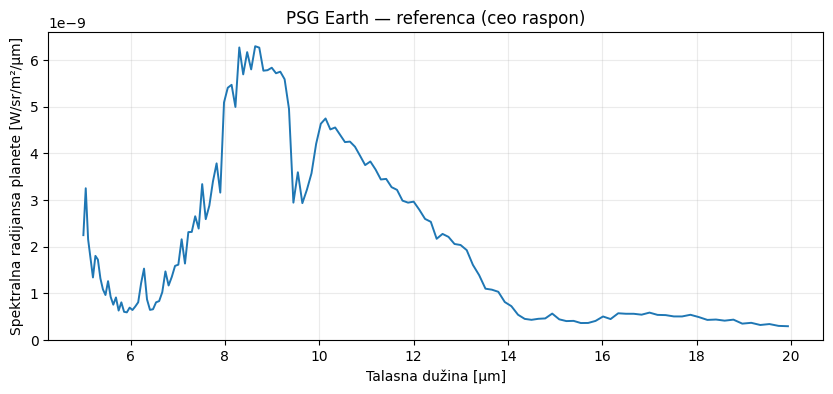

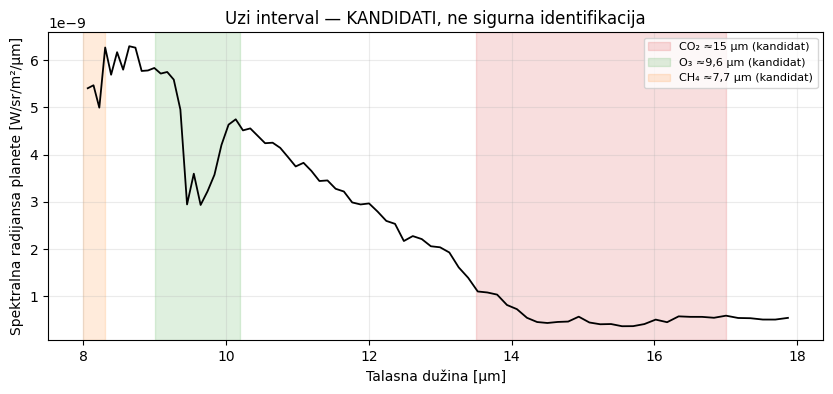

In [15]:
REF_TXT = DATA_DIR / 'earth_ref.txt'

def header_comments(path):
    #Samo linije zaglavlja 
    return [l for l in Path(path).read_text(encoding='utf-8-sig', errors='replace').splitlines()
            if l.strip().startswith('#')]

df_ref, hdr_ref = inspect_psg_ascii(REF_TXT)
print('\n--- ZAGLAVLJE (# linije) ---')
print('\n'.join(header_comments(REF_TXT)[:20]))


X_COL, Y_COL = 'col_0', 'col_3'          
X_LABEL = 'Talasna dužina [µm]'  
Y_LABEL = 'Spektralna radijansa planete [W/sr/m²/µm]'

# Cilj: provera opsega iz .cfg vs. izvezeni opseg
x = df_ref[X_COL].to_numpy(float)
print(f'\nIzvezeni opseg: {x.min():.4g} – {x.max():.4g}  ({len(x)} tacaka)')
try:
    cfg_ref = parse_cfg(DATA_DIR / 'earth_ref.cfg')
    print('Iz .cfg:', cfg_ref.get('GENERATOR-RANGE1'), cfg_ref.get('GENERATOR-RANGE2'),
          cfg_ref.get('GENERATOR-RANGEUNIT'), '| R =', cfg_ref.get('GENERATOR-RESOLUTION'),
          cfg_ref.get('GENERATOR-RESOLUTIONUNIT'), '| RADUNITS =', cfg_ref.get('GENERATOR-RADUNITS'))
except FileNotFoundError:
    print('earth_ref.cfg nije pronadjen - uporedi opseg rucno.')

# Kandidati za molekule (granice su ORIJENTACIONE)
BANDS = {'CO₂ ≈15 µm': (13.5, 17.0), 'O₃ ≈9,6 µm': (9.0, 10.2),
         'H₂O ≈6,3 µm': (5.5, 7.5), 'CH₄ ≈7,7 µm': (7.3, 8.3)}

# Grafik 1: ceo raspon
plot_selected_columns(df_ref, X_COL, Y_COL, X_LABEL, Y_LABEL, 'PSG Earth — referenca (ceo raspon)')

# Grafik 2: uzi interval sa oznacenim kandidatima
order = np.argsort(x); xs = x[order]; ys = df_ref[Y_COL].to_numpy(float)[order]
lo, hi = 8.0, 18.0                        # <-- uzi interval od interesa
m = (xs >= lo) & (xs <= hi)
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(xs[m], ys[m], lw=1.3, color='k')
for (name,(a,b)), c in zip(BANDS.items(), ['tab:red','tab:green','tab:blue','tab:orange']):
    if b >= lo and a <= hi:
        ax.axvspan(max(a,lo), min(b,hi), color=c, alpha=.15, label=name + ' (kandidat)')
ax.set(xlabel=X_LABEL, ylabel=Y_LABEL, title='Uzi interval — KANDIDATI, ne sigurna identifikacija')
ax.legend(fontsize=8); ax.grid(alpha=.25); plt.show()

**Komentar studenta - Zadatak 3 (molekuli, intervali, jedinice):**

Fajl `earth_ref.txt` ima 140 tačaka (153 redova, od kojih je 13 zaglavlje) u opsegu 5–19,94 µm na logaritamskoj mreži sa korakom oko 1 %, što odgovara R = 100 iz `.cfg` (zadato 5–20 µm, `RADUNITS = Wsrm2um`). Prema zaglavlju, `col_0` je talasna dužina [µm], `col_1` je *Total* (zvezda + planeta), `col_2` je *Stellar*, a `col_3` je *Earth* (planetarna komponenta). Veličina je spektralna radijansa [W/sr/m²/µm]. Pošto je *Total* praktično samo zvezda (Earth/Stellar ≈ 2·10⁻⁷ na 10 µm), analiza se radi na `col_3`.

**Opažanja (iz grafika):** signal planete ima maksimum ≈6,3·10⁻⁹ oko 8,3–8,7 µm i zadržava se na ≈5,8·10⁻⁹ do ≈9,3 µm. Zatim se javlja oštro udubljenje oko 9,4–9,7 µm (minimum ≈2,9·10⁻⁹ na 9,64 µm), nakon čega se signal oporavlja do ≈4,7·10⁻⁹ na ≈10,1 µm. Potom opada, a na ≈13,5 µm pada na ≈10⁻⁹ i dostiže široko nisko područje od oko 14 do 16 µm (≈4–6·10⁻¹⁰, minimum 3,65·10⁻¹⁰ na 15,5 µm). Ispod ≈8 µm signal jako varira (≈0,6–1,5·10⁻⁹), a susedne tačke se razlikuju oko 9 %, iako je šum isključen.

**Interpretacija (kandidati, ne sigurna identifikacija):** široko nisko područje oko 14–16 µm je kandidat za CO₂ (ν₂ pojas); njegov oblik je široka depresija, a ne uski pojedinačni minimum. Udubljenje na ≈9,6 µm je kandidat za O₃. Struktura ispod ≈8 µm je kandidat za H₂O (i CH₄/N₂O oko 7,7 µm). Kao dodatni dokaz služi transmitansa iz `psg_trn.txt` (drugi tip veličine, pa se ne poredi direktno sa radijansom): CO₂ je neproziran oko 14,9 µm, O₃ ima minimum ≈0,36 oko 9,45 µm, a H₂O je neproziran oko 6,6 µm.

**Ograničenja:** pojasevi se preklapaju (npr. CH₄ i N₂O oko 7,7 µm), a oblik pojasa zavisi i od temperaturnog profila. Varijacije između susednih tačaka na 5–8 µm verovatno potiču od uzorkovanja linijske strukture pri R = 100, a ne od šuma, ali to nisam posebno proveravao.

## Zadatak 4 - Atmosferski scenario

1. Napravite kopiju referentnog podešavanja i promenite **samo CO₂**, npr. faktorsku promenu abundance koju model podržava. Zapišite tačnu vrednost i jedinicu **pre i posle**.
2. Potvrdite da li je promenjen željeni **vertikalni profil** ili samo nominalno polje u GUI-ju.
3. Ponovo generišite spektar uz **identičnu geometriju, opseg, instrument, jedinice i druge atmosferske parametre**.
4. Sačuvajte `earth_variant.cfg` i odgovarajući originalni ASCII izlaz `earth_variant.txt`.
5. Uporedite `.cfg` fajlove pomoću `compare_cfg`; ispitajte neočekivane promene i obrazložite ih. Ako se uz CO₂ promenio i drugi parametar, scenario označite kao **nepotpuno kontrolisan**.

**Predajte:** oba `.cfg`, opis kontrolisane promene i proveru profila. Ako nemate dozvoljen način za promenu CO₂, nemojte ručno izmišljati PSG izlaze.

--- REFERENCE
+++ VARIANT
@@ -81,7 +81,7 @@
 <ATMOSPHERE-NGAS>8
 <ATMOSPHERE-GAS>H2O,CO2,O3,N2O,CO,CH4,O2,N2
 <ATMOSPHERE-TYPE>HIT[1],HIT[2],HIT[3],HIT[4],HIT[5],HIT[6],HIT[7],HIT[22]
-<ATMOSPHERE-ABUN>1,1,1,1,1,1,1,1
+<ATMOSPHERE-ABUN>1,2,1,1,1,1,1,1
 <ATMOSPHERE-UNIT>scl,scl,scl,scl,scl,scl,scl,scl
 <ATMOSPHERE-LAYERS-MOLECULES>H2O,CO2,O3,N2O,CO,CH4,O2,NO,SO2,NO2,NH3,HNO3,OH,HF,HCl,HBr,HI,ClO,OCS,H2CO,HOCl,N2,HCN,CH3Cl,H2O2,C2H2,C2H6,PH3,WaterIce
 <ATMOSPHERE-LAYERS>71

Broj promenjenih kljuceva: 1
  ATMOSPHERE-ABUN:
     REF: 1,1,1,1,1,1,1,1
     VAR: 1,2,1,1,1,1,1,1


,CO2_var/ref,dT
min,1.0,0.0
mean,1.0,0.0
max,1.0,0.0


Ako je CO2_var/ref ~ konstantan faktor po svim slojevima, a dT ~ 0 -> promena je kontrolisana.


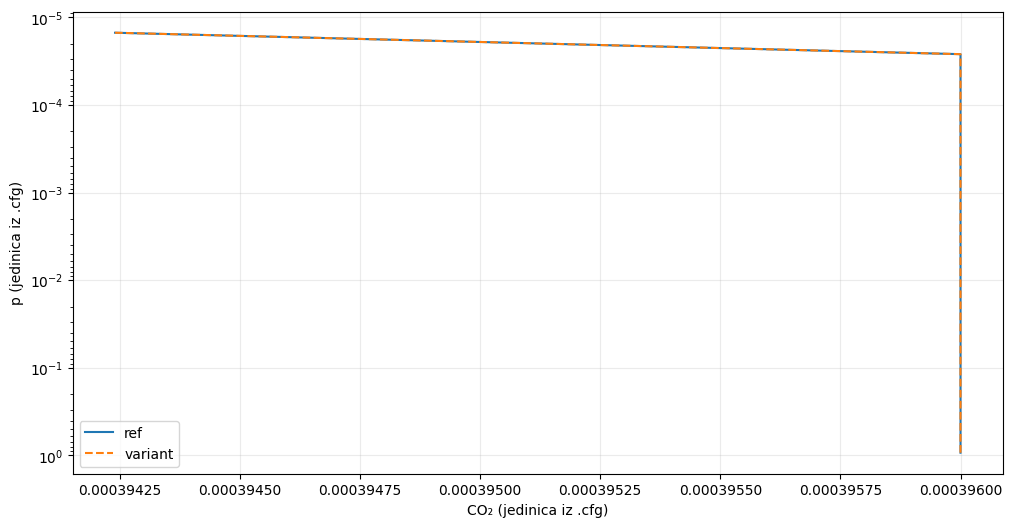

In [23]:
REF_CFG = DATA_DIR / 'earth_ref.cfg'
VAR_CFG = DATA_DIR / 'earth_variant.cfg'

changes = compare_cfg(REF_CFG, VAR_CFG)

# Koji su KLJUCEVI promenjeni (pregledniji nego diff)
cr, cv = parse_cfg(REF_CFG), parse_cfg(VAR_CFG)
changed = {k: (cr.get(k), cv.get(k)) for k in sorted(set(cr) | set(cv)) if cr.get(k) != cv.get(k)}
print(f'\nBroj promenjenih kljuceva: {len(changed)}')
for k, (a, b) in changed.items():
    sa = (' | '.join(a) if a else '—')[:90]; sb = (' | '.join(b) if b else '—')[:90]
    print(f'  {k}:\n     REF: {sa}\n     VAR: {sb}')

# 3) Provera VERTIKALNOG profila CO2 (da li je promenjen profil, a ne samo nominalno polje)
pr, pv = co2_profile(cr), co2_profile(cv)
if pr is not None and pv is not None and len(pr) == len(pv):
    cmp_ = pr.rename(columns={'CO2':'CO2_ref','T':'T_ref'}).copy()
    cmp_['CO2_var'] = pv['CO2'].values
    cmp_['T_var']   = pv['T'].values
    cmp_['CO2_var/ref'] = cmp_['CO2_var'] / cmp_['CO2_ref']
    cmp_['dT'] = cmp_['T_var'] - cmp_['T_ref']
    display(cmp_.describe().loc[['min','mean','max'], ['CO2_var/ref','dT']])
    print('Ako je CO2_var/ref ~ konstantan faktor po svim slojevima, a dT ~ 0 -> promena je kontrolisana.')
    fig, ax = plt.subplots(figsize=(12,6))
    ax.plot(pr['CO2'], pr['p'], label='ref'); ax.plot(pv['CO2'], pv['p'], '--', label='variant')
    ax.set_yscale('log'); ax.invert_yaxis(); ax.set(xlabel='CO₂ (jedinica iz .cfg)', ylabel='p (jedinica iz .cfg)')
    ax.legend(); ax.grid(alpha=.25); plt.show()
else:
    print('Slojevi nisu nadjeni/uporedivi u .cfg - proveri profile u PSG GUI (Atmosphere tab) i zapisi rucno.')

**Komentar studenta - Zadatak 4 (šta je zaista promenjeno i kako je provereno):**

- **Menjani parametar:** CO₂, preko *scaler* faktora u PSG-u (Composition → CO₂ → Abundance). **Pre:** 1 (`ATMOSPHERE-ABUN = 1,1,1,1,1,1,1,1`). **Posle:** 2 (`ATMOSPHERE-ABUN = 1,2,1,1,1,1,1,1`). Pošto je referentni profil Earth Standard sa ≈396 ppm CO₂, efektivna vrednost je ≈792 ppm (udvostručenje).
- **Šta je diff pokazao:** `compare_cfg` prijavljuje **tačno jedan promenjen ključ** (`ATMOSPHERE-ABUN`), svi ostali ključevi su identični (opseg, R = 100, jedinica, šum isključen, geometrija, površina, ostali gasovi, aerosoli). Scenario je zato **kontrolisan**: promenjena je samo CO₂ abundanca.
- **Provera vertikalnog profila:** odnos CO₂_var/CO₂_ref po svim slojevima iznosi 1,0, a ΔT = 0. To je očekivano: PSG udvostručenje primenjuje kao faktor (`scl`) pri računanju spektra, a ne upisuje promenjene vrednosti u slojeve `.cfg`. Zato sama provera slojeva ne dokazuje udvostručenje; dokaz je vrednost scalera u `ATMOSPHERE-ABUN` i razlika u spektrima (Zadatak 5). Temperaturni profil je nepromenjen, tako da su efekti čist uticaj CO₂.
- **Napomena:** `ATMOSPHERE-WEIGHT` (srednja molekulska masa) se nije promenio, što je zanemarljivo za udvostručenje sa ≈396 ppm CO₂. Promena je uniformna po visini (isti faktor u svim slojevima), pa ne testira posebno uticaj vertikalne raspodele CO₂.

## Zadatak 5 - Uporedite spektre i identifikujte atmosferske karakteristike 

1. Učitajte referentni i izmenjeni ASCII izlaz. Iz zaglavlja **nezavisno za svaki** potvrdite koordinatu i njenu jedinicu, tip veličine i jedinicu y-ose.
2. Na zajedničkom grafiku preklopite oba spektra. Ako spektralne mreže nisu identične, interpolirajte jedan spektar na drugi **samo u preseku domena** i navedite postupak.
3. Izračunajte $\Delta F=F_\mathrm{variant}-F_\mathrm{ref}$ i, samo gde je bezbedno, relativnu razliku.
4. Označite najmanje **tri spektralna intervala** od interesa i moguće molekule (ako opseg dozvoljava). Ako je posmatran samo jedan jasan interval, objasnite zašto nema drugih.
5. Za CO₂ objasnite da li se posmatrana promena uklapa u očekivanja. Obratite pažnju na saturaciju i temperaturni profil: „više CO₂ = dublja apsorpcija svuda“ nije univerzalno pravilo.

**Predajte:** preklopljene krive, grafik razlike i tabelu *interval–kandidat molekula–dokaz–ograničenje*.

Fajl: earth_ref.txt; ukupno redova: 153
--- PRVI REDOVI ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Tue Nov 10 19:08:53 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,-0.00000,0.00000,73.41404,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 0.386 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
--- DIMENZIJE --- (140, 4)


,col_0,col_1,col_2,col_3
0,5.000000,1.356266,1.35627,2.247630e-09
1,5.050000,1.281077,1.28108,3.252180e-09
2,5.100500,1.210023,1.21002,2.156150e-09
3,5.151505,1.142877,1.14288,1.750540e-09
4,5.203020,1.079428,1.07943,1.341720e-09


Fajl: earth_variant.txt; ukupno redova: 153
--- PRVI REDOVI ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Wed Nov 18 18:27:24 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,-0.00000,0.00000,73.41404,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 0.415 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
--- DIMENZIJE --- (140, 4)


,col_0,col_1,col_2,col_3
0,5.000000,1.356266,1.35627,2.247390e-09
1,5.050000,1.281077,1.28108,3.251150e-09
2,5.100500,1.210023,1.21002,2.154440e-09
3,5.151505,1.142877,1.14288,1.748630e-09
4,5.203020,1.079428,1.07943,1.335270e-09


Mreze identicne: True | presek domena: 5 – 19.94 | N = 140
Postupak: bez interpolacije


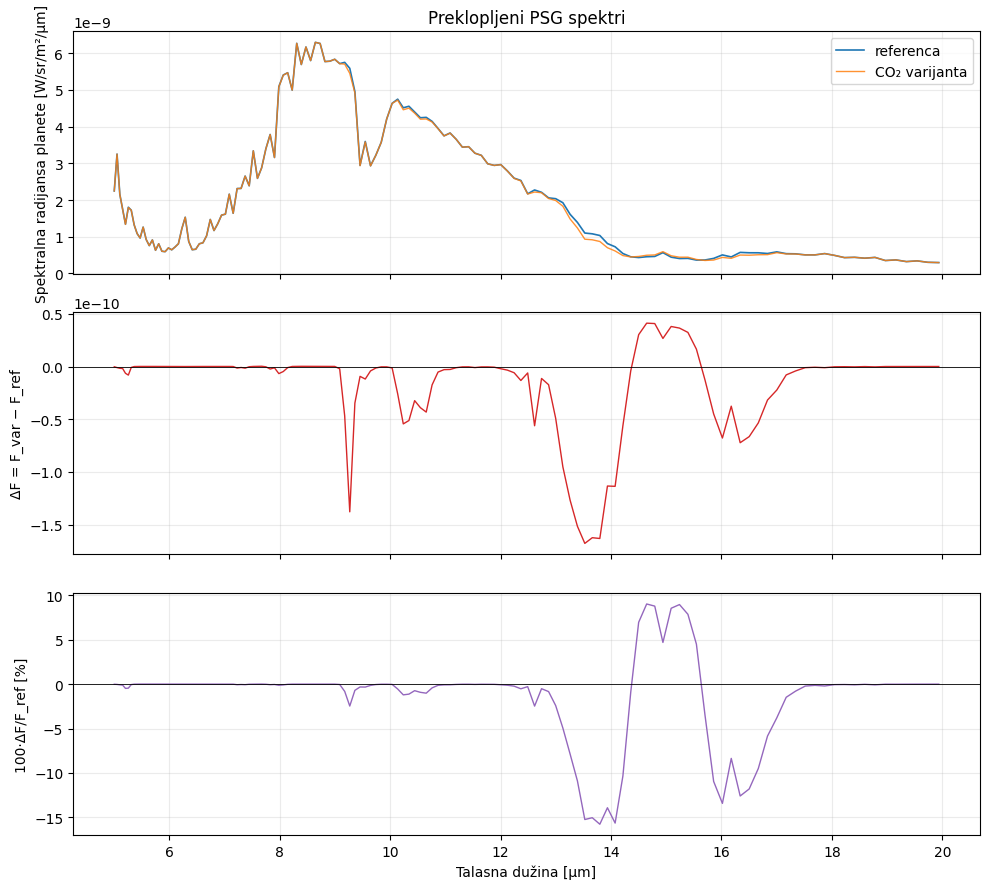

,kandidat,interval [µm],pokrivenost,<F_ref>,<ΔF>,max|ΔF|
0,CO₂ ≈15 µm,13.5–17.0,23 tacaka,5.772998e-10,-3.941452e-11,1.678650e-10
1,"O₃ ≈9,6 µm",9.0–10.2,12 tacaka,4.321608e-09,-2.304917e-11,1.379000e-10
2,"H₂O ≈6,3 µm",5.5–7.5,31 tacaka,1.213957e-09,-1.064194e-13,1.610000e-12
3,"CH₄ ≈7,7 µm",7.3–8.3,12 tacaka,3.762418e-09,-1.489167e-12,6.750000e-12


In [22]:
REF_TXT = DATA_DIR / 'earth_ref.txt'
VAR_TXT = DATA_DIR / 'earth_variant.txt'

df_r, _ = inspect_psg_ascii(REF_TXT, preview_lines=12)
df_v, _ = inspect_psg_ascii(VAR_TXT, preview_lines=12)

# >>> NEZAVISNO potvrdi iz zaglavlja svakog fajla (koordinata, jedinica, tip velicine, jedinica y)
XR, YR = 'col_0', 'col_3'   # col_3 = 'Earth' (planetarna komponenta); col_1 'Total' je dominiran zvezdom
XV, YV = 'col_0', 'col_3'
X_LABEL = 'Talasna dužina [µm]'
Y_LABEL = 'Spektralna radijansa planete [W/sr/m²/µm]'

def sorted_xy(df, xc, yc):
    x = df[xc].to_numpy(float); y = df[yc].to_numpy(float)
    o = np.argsort(x); return x[o], y[o]

xr, yr = sorted_xy(df_r, XR, YR)
xv, yv = sorted_xy(df_v, XV, YV)

# Zajednicka mreza: interpolacija VARIJANTE na mrezu reference, samo u preseku domena (bez ekstrapolacije)
lo, hi = max(xr.min(), xv.min()), min(xr.max(), xv.max())
mask = (xr >= lo) & (xr <= hi)
x = xr[mask]; F1 = yr[mask]
same_grid = (len(xr) == len(xv)) and np.allclose(xr, xv, rtol=1e-9, atol=0)
F2 = yv.copy() if same_grid else np.interp(x, xv, yv)[:]
if same_grid: F2 = F2[mask]
print('Mreze identicne:', same_grid, '| presek domena:', f'{lo:.4g} – {hi:.4g}', '| N =', len(x))
print('Postupak:', 'bez interpolacije' if same_grid else 'linearna interpolacija varijante na mrezu reference u preseku domena')

dF = F2 - F1
with np.errstate(divide='ignore', invalid='ignore'):
    rel = np.where(np.abs(F1) > 1e-3*np.nanmax(np.abs(F1)), 100*dF/F1, np.nan)   # relativno samo gde je F1 dovoljno veliko

fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axs[0].plot(x, F1, label='referenca', lw=1.2); axs[0].plot(x, F2, label='CO₂ varijanta', lw=1.0, alpha=.85)
axs[0].set_ylabel(Y_LABEL); axs[0].legend(); axs[0].grid(alpha=.25); axs[0].set_title('Preklopljeni PSG spektri')
axs[1].plot(x, dF, color='tab:red', lw=1.0); axs[1].axhline(0, color='k', lw=.6)
axs[1].set_ylabel('ΔF = F_var − F_ref'); axs[1].grid(alpha=.25)
axs[2].plot(x, rel, color='tab:purple', lw=1.0); axs[2].axhline(0, color='k', lw=.6)
axs[2].set_ylabel('100·ΔF/F_ref [%]'); axs[2].set_xlabel(X_LABEL); axs[2].grid(alpha=.25)
plt.tight_layout(); plt.show()

# Tabela intervala: kandidati, srednje F_ref/F_var u intervalu i ΔF (prilagodi granice svojim podacima)
BANDS = {'CO₂ ≈15 µm': (13.5, 17.0), 'O₃ ≈9,6 µm': (9.0, 10.2),
         'H₂O ≈6,3 µm': (5.5, 7.5), 'CH₄ ≈7,7 µm': (7.3, 8.3)}
rows = []
for name, (a, b) in BANDS.items():
    mm = (x >= a) & (x <= b)
    if mm.sum() < 3:
        rows.append((name, f'{a}–{b}', 'van opsega / premalo tacaka', np.nan, np.nan, np.nan)); continue
    i_min = np.argmin(F1[mm])
    rows.append((name, f'{a}–{b}', f'{mm.sum()} tacaka', np.mean(F1[mm]), np.mean(dF[mm]), np.max(np.abs(dF[mm]))))
tab = pd.DataFrame(rows, columns=['kandidat','interval [µm]','pokrivenost','<F_ref>','<ΔF>','max|ΔF|'])
display(tab)

**Komentar studenta - Zadatak 5 (tabela opsega i interpretacija):**

Obe simulacije imaju identičnu talasnu mrežu (140 tačaka, 5–19,94 µm), pa je razlika ΔF = F_var − F_ref računata direktno, bez interpolacije. Jedina razlika u konfiguraciji je CO₂ × 2 (Zadatak 4).

| Interval [µm] | Kandidat | Dokaz (iz mojih podataka) | Ograničenje |
|---|---|---|---|
| 13,5–17 | CO₂ (ν₂ pojas) | Najveća promena: max \|ΔF\| = 1,68·10⁻¹⁰ (oko 13,5 µm, ≈ −15 %); ⟨ΔF⟩ = −3,9·10⁻¹¹ naspram ⟨F_ref⟩ = 5,8·10⁻¹⁰ (≈ −7 %). Znak se menja: ΔF < 0 na ≈13–14,2 µm i ≈15,7–17 µm, a ΔF > 0 na ≈14,4–15,5 µm (do ≈ +4·10⁻¹¹, ≈ +9 %). | Srednja vrednost ⟨ΔF⟩ potcenjuje efekat jer se pozitivni i negativni delovi poništavaju; saturacija i temperaturni profil određuju znak |
| 9–10,2 | O₃ (ali menjan je samo CO₂) | max \|ΔF\| = 1,38·10⁻¹⁰ oko 9,3 µm (≈ −2,5 %), manje promene oko 10 µm (≈ −1 %); ⟨ΔF⟩ = −2,3·10⁻¹¹ (≈ −0,5 %) | Pošto je O₃ nepromenjen, ova razlika mora poticati od CO₂ (verovatno slabiji CO₂ pojasevi oko 9,4 i 10,4 µm, što je pretpostavka); udubljenje O₃ samo se preklapa |
| 5,5–7,5 | H₂O | ⟨ΔF⟩ = −1,1·10⁻¹³, max \|ΔF\| = 1,6·10⁻¹² (≈ 0,1 %) | Služi kao kontrola: nepromenjeni gas daje praktično nultu promenu |
| 7,3–8,3 | CH₄ (i N₂O) | ⟨ΔF⟩ = −1,5·10⁻¹², max \|ΔF\| = 6,8·10⁻¹² (≈ 0,2 %) | Isto: kontrola; preklapanje CH₄/N₂O ne može se razdvojiti iz ovog eksperimenta |

**Interpretacija CO₂:** Udvostručenje CO₂ ne menja spektar srazmerno svuda. Centar pojasa je već optički debeo, pa je promena koncentrisana u krilima i unutar pojasa menja i znak. U krilima (≈13–14,2 µm i ≈15,7–17 µm) ΔF je negativan: više CO₂ podiže nivo iz kojeg zračenje izlazi u hladnije slojeve, pa je emisija manja. Oko centra (≈14,4–15,5 µm) ΔF je pozitivan. To je u skladu sa temperaturnim profilom iz PSG-a, gde temperatura iznad tropopauze raste (stratosfera), pa dodatni CO₂ u visokim slojevima povećava emisiju iz toplijeg sloja (interpretacija, nisam je posebno proveravao).

**Zašto je CO₂ jedini jasan odgovor:** promenjen je samo CO₂, pa sve razlike u spektru pripisujemo njemu. Pojasevi H₂O i CH₄ ostaju praktično identični, što pokazuje da eksperiment ne unosi druge promene. Razlika oko 9–10 µm nije dokaz za O₃, jer O₃ nije menjan.

**Šum i oscilacije:** ΔF je praktično nula van pojasa (npr. 6–9 µm), iako referentni spektar ima oscilacije između susednih tačaka. Pošto se te oscilacije ponavljaju u oba spektra i poništavaju se u razlici, one su determinističke (uzorkovanje linijske strukture pri R = 100), a ne nasumični šum, što razrešava napomenu iz Zadatka 3.

**Ograničenja:** model je bezoblačan, jedan geometrijski slučaj (fazni ugao ≈ 90°), bez šuma instrumenta. Promena je izolovana po jednom parametru, pa ne pokazuje degeneracije sa temperaturnim profilom ili oblacima.

## Zadatak 6 - Uloga instrumentalne rezolucije 

1. Zapišite izabranu spektralnu rezoluciju $R$ i izračunajte $\Delta\lambda$ na najmanje dve talasne dužine.
2. Ako PSG omogućava, generišite **dodatni stvarni PSG izlaz** sa drugačijim $R$, pri istoj geometriji i atmosferi. Sačuvajte `.cfg` i ASCII i uporedite spektralne pojaseve. **Alternativa:** naknadna konvolucija istog izlaza, jasno označena kao aproksimacija u Pythonu, *ne PSG instrument model*.
3. Razdvojite konvoluciju, uzorkovanje i fizički instrumentalni šum. Zašto veća rezolucija nije isto što i automatski bolja detekcija?
4. Navedite jedan instrumentalan efekat koji bi mogao da zamaskira slabu liniju.

**Predajte:** izračunate $\Delta\lambda$, grafik ili argumentovano poređenje i komentar.

R = 100:  λ =  9.6 µm  ->  Δλ ≈ 0.096 µm
R = 100:  λ = 15.0 µm  ->  Δλ ≈ 0.150 µm

FWHM pri R=20: 0.48 µm na 9,6 µm; 0.75 µm na 15 µm
O₃ ≈9,6 µm: min(F) pri R=100: 2.933e-09 | pri R≈20: 3.599e-09 | promena minimuma: +23 %
CO₂ ≈15 µm: min(F) pri R=100: 3.651e-10 | pri R≈20: 4.119e-10 | promena minimuma: +13 %
Medijana relativnog skoka između susednih tačaka: R=100: 9.3 %, R≈20: 4.9 %


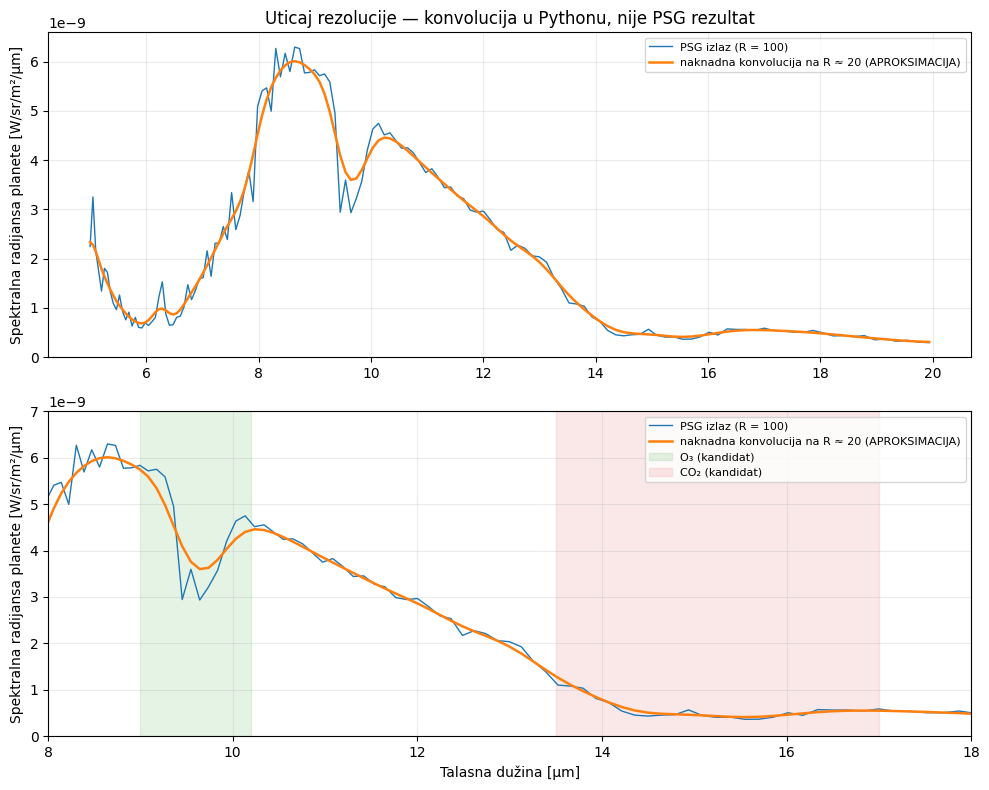

In [ ]:
# 6.1 Rezolucija iz earth_ref.cfg: GENERATOR-RESOLUTION = 100 (RP, resolving power)
R_CHOSEN = 100
for lam in (9.6, 15.0):
    print(f'R = {R_CHOSEN}:  λ = {lam:>4} µm  ->  Δλ ≈ {lam/R_CHOSEN:.3f} µm')

# Podaci: planetarna komponenta ('Earth', col_3) iz earth_ref.txt, ucitano ponovo da ćelija bude samostalna
_ref = np.loadtxt(DATA_DIR / 'earth_ref.txt', comments='#')
xr, yr = _ref[:, 0], _ref[:, 3]          

# 6.2 Naknadna Gaussova konvolucija — APROKSIMACIJA U PYTHONU, NIJE PSG INSTRUMENT MODEL
def degrade_resolution(x, y, R_target, R_native=None):
    """Gaussova konvolucija na uniformnoj mreži u ln(λ)"""
    x = np.asarray(x, float); y = np.asarray(y, float)
    lx = np.log(x)
    grid = np.linspace(lx.min(), lx.max(), len(x))
    yg = np.interp(grid, lx, y)
    dlnl = grid[1] - grid[0]
    fwhm_ln = 1.0 / R_target                       # FWHM u ln(λ)
    if R_native:                                   # oduzmi već postojeću širinu (R=100 iz PSG-a)
        fwhm_ln = np.sqrt(max(fwhm_ln**2 - (1.0 / R_native)**2, 0.0))
    sigma_pix = fwhm_ln / (2*np.sqrt(2*np.log(2))) / dlnl
    ys = gaussian_filter1d(yg, sigma_pix, mode='nearest')
    return np.exp(grid), ys

R_LOW = 20                                          # niži R od izvornog (R = 100)
xl, yl = degrade_resolution(xr, yr, R_target=R_LOW, R_native=R_CHOSEN)

# Kvantitativno poređenje na kandidatima (vrednosti iz mojih podataka)
yl_on_x = np.interp(xr, xl, yl)
print(f'\nFWHM pri R={R_LOW}: {9.6/R_LOW:.2f} µm na 9,6 µm; {15.0/R_LOW:.2f} µm na 15 µm')
for name, (a, b) in {'O₃ ≈9,6 µm': (9.0, 10.2), 'CO₂ ≈15 µm': (13.5, 17.0)}.items():
    m = (xr >= a) & (xr <= b)
    print(f'{name}: min(F) pri R={R_CHOSEN}: {yr[m].min():.3e} | pri R≈{R_LOW}: {yl_on_x[m].min():.3e} '
          f'| promena minimuma: {100*(yl_on_x[m].min()/yr[m].min()-1):+.0f} %')
rough = lambda y: np.median(np.abs(np.diff(y)) / y[1:])
print(f'Medijana relativnog skoka između susednih tačaka: R={R_CHOSEN}: {100*rough(yr):.1f} %, '
      f'R≈{R_LOW}: {100*rough(yl_on_x):.1f} %')

# Grafik: ceo raspon + uvećan interval sa pojasevima
fig, axs = plt.subplots(2, 1, figsize=(10, 8))
for ax in axs:
    ax.plot(xr, yr, lw=1.0, label=f'PSG izlaz (R = {R_CHOSEN})')
    ax.plot(xl, yl, lw=1.8, label=f'naknadna konvolucija na R ≈ {R_LOW} (APROKSIMACIJA)')
    ax.set_ylabel('Spektralna radijansa planete [W/sr/m²/µm]')
    ax.grid(alpha=.25); ax.legend(fontsize=8)
axs[0].set_title('Uticaj rezolucije — konvolucija u Pythonu, nije PSG rezultat')
axs[1].set_xlim(8, 18)
axs[1].set_ylim(0, 7e-9)
axs[1].axvspan(9.0, 10.2, color='tab:green', alpha=.12, label='O₃ (kandidat)')
axs[1].axvspan(13.5, 17.0, color='tab:red', alpha=.10, label='CO₂ (kandidat)')
axs[1].legend(fontsize=8)
axs[1].set_xlabel('Talasna dužina [µm]')
plt.tight_layout(); plt.show()

**Komentar studenta - Zadatak 6:**

**6.1 Račun.** Iz `earth_ref.cfg`: `GENERATOR-RESOLUTION = 100` (resolving power). Iz Δλ ≈ λ/R: na 9,6 µm Δλ ≈ 0,096 µm, a na 15 µm Δλ ≈ 0,150 µm. Detalji uži od toga se ne razdvajaju. Pojas O₃ (širok oko 1 µm) i pojas CO₂ (širok nekoliko µm) su tom rezolucijom jasno razlučeni.

**6.2 Poređenje.** Pošto nemam drugi PSG izlaz sa drugačijim R, upotrebio sam naknadnu Gaussovu konvoluciju referentnog spektra (`col_3`, planeta) na R ≈ 20. To je **aproksimacija u Pythonu, a ne PSG model instrumenta**. Pri R ≈ 20 je FWHM ≈ 0,48 µm na 9,6 µm i ≈ 0,75 µm na 15 µm.

Na grafiku se vidi:
- **O₃ (≈9,6 µm):** udubljenje ostaje, ali je šire i pliće. Oštra ivica oko 9,3–9,4 µm i dvostruki minimum nestaju. Minimum raste sa 2,93·10⁻⁹ na 3,60·10⁻⁹ (+23 %).
- **CO₂ (≈14–16 µm):** široko nisko područje se praktično zadržava, a minimum raste sa 3,65·10⁻¹⁰ na 4,12·10⁻¹⁰ (+13 %). Pošto je ovaj pojas širok, konvolucija ga menja manje nego uži O₃ pojas.
- **5–8 µm:** fina struktura (verovatno H₂O i CH₄/N₂O) je uglavnom izglačana, ostaje samo opšti oblik.
- Medijana relativnog skoka između susednih tačaka pada sa 9,3 % na 4,9 %, pa oscilacije iz Zadatka 3 izgledaju kao fina linijska struktura koju niža rezolucija briše. To je u skladu sa tim objašnjenjem, ali ga ne dokazuje.

**6.3 Konvolucija, uzorkovanje, šum.** *Konvolucija* širi svaku liniju instrumentalnom funkcijom (LSF) i smanjuje dubinu uskih linija; *uzorkovanje* (gustina tačaka) ne menja fizičku rezoluciju; *šum* je nasumična ili sistematska greška. Veće R razdvaja uže linije, ali svaki rezolucioni element prima manje fotona, pa SNR po elementu opada. Zato veće R nije automatski bolja detekcija: za široke pojaseve (CO₂ na 15 µm) niži R sa višim SNR je često povoljniji.

**6.4 Efekat koji maskira slabu liniju:** (1) zvezdana svetlost: u ovom spektru je Earth/Stellar ≈ 10⁻⁷, pa i mala nesavršenost oduzimanja zvezde može da prekrije planetarnu liniju; (2) fotonski i detektorski šum, koji je ovde isključen, ali bi u pravom merenju bio presudan; (3) smanjena rezolucija koja razmazuje usku liniju (kao O₃ ivica iznad) tako da pliće udubljenje padne ispod nivoa šuma.

## Zadatak 7 - Naučni memo 

Napišite **200–300 reči** i odgovorite na pitanje „Da je Zemlja egzoplaneta: šta bismo mogli da zaključimo iz ovog PSG spektra?“

Obavezno uključite: (a) režim i geometriju, (b) konkretne gasove i intervale iz vaših izlaza, (c) koja je promena CO₂ i da li je kontrolisana, (d) šta znači instrumentalna rezolucija i (e) tri ograničenja zaključivanja o nastanjivosti i biosignaturama.

**Posebno obeležite šta je: opažanje/izvezeni podatak; modelska pretpostavka; interpretacija.** Ne nazivajte simulaciju posmatranjem egzoplanete.

**Memo studenta - Zadatak 7:**

**(a) Režim i geometrija.** **[MODELSKA PRETPOSTAVKA]** Simulirana je termalna emisija Zemlje u srednjem IR u PSG-u: disk-integrisan spektar bezoblačne atmosfere (Earth Standard, 71 sloj, 1 bar, 288 K) sa posmatračem na 10 pc, faznim uglom ≈ 90° (izveden iz uglova posmatrača), opsegom 5–20 µm i idealizovanim instrumentom R = 100 bez šuma. Ovo je simulacija, ne posmatranje egzoplanete.

**(b) Gasovi i intervali.** **[OPAŽANJE/PODATAK]** U planetarnoj komponenti `earth_ref.txt` (W/sr/m²/µm) vidi se oštro udubljenje oko 9,64 µm (2,9·10⁻⁹ naspram ≈5,7·10⁻⁹ na 9,3 µm) i široko nisko područje na 14–16 µm (minimum 3,7·10⁻¹⁰ na 15,5 µm), uz promenljivu strukturu ispod 8 µm. **[INTERPRETACIJA]** To su kandidati za O₃, CO₂ i H₂O/CH₄; pripisivanje je dvosmisleno zbog preklapanja pojaseva.

**(c) Promena CO₂.** **[MODELSKA PRETPOSTAVKA]** CO₂ je udvostručen (scaler 1 → 2, ≈396 → ≈792 ppm); diff pokazuje tačno jedan promenjen ključ, pa je scenario kontrolisan. **[OPAŽANJE/PODATAK]** Najveća razlika je |ΔF| = 1,7·10⁻¹⁰ na ≈13,5 µm (≈ −15 %), a u kontrolnom H₂O intervalu ≤ 1,6·10⁻¹² (≈ 0,1 %). Znak se menja: ΔF > 0 na ≈14,4–15,5 µm (do ≈ +9 %). **[INTERPRETACIJA]** Promena nije srazmerna svuda: centar pojasa je saturisan, a pozitivan znak verovatno odražava stratosferski temperaturni profil (nije posebno proveravano).

**(d) Rezolucija.** Δλ = λ/R ≈ 0,15 µm na 15 µm. Konvolucija na R ≈ 20 (aproksimacija u Pythonu) podiže minimum O₃ za 23 %, a CO₂ za 13 %. Veće R ne znači bolju detekciju jer SNR po elementu opada.

**(e) Ograničenja.** (1) CO₂, O₃ i H₂O govore o atmosferi, ne o životu; O₃ i O₂ mogu nastati i abiotički. (2) Model je bezoblačan, ima jedan fazni ugao, nema šuma ni zvezdane kontaminacije (Earth/Stellar ≈ 2·10⁻⁷), a T–p profil i sastav su degenerisani. (3) Nastanjivost zavisi i od površine, fluksa i istorije planete, što ovaj spektar ne daje.


## Reference i alati

- [NASA PSG — početna strana](https://psg.gsfc.nasa.gov/)
- [NASA PSG — uputstvo za rad i konfiguracije](https://psg.gsfc.nasa.gov/help.php)
- [NASA PSG — atmosferski profili i jedinice](https://psg.gsfc.nasa.gov/helpatm.php)
- [NASA PSG — API i tipovi ASCII izlaza](https://psg.gsfc.nasa.gov/helpapi.php)
- [NASA PSG — priručnik](https://psg.gsfc.nasa.gov/images/help/handbook.pdf)
